# Nghiên cứu giai đoạn 1: ảnh lá dược liệu, SVM và tối ưu
Notebook này đọc và kiểm tra **kết quả chạy thật đã lưu**. Không tự huấn luyện lại hoặc chấm tập test. Để tái lập huấn luyện, dùng lệnh ở cuối notebook.

Dữ liệu: [BDMediLeaves 6 loài](https://data.mendeley.com/datasets/t9rns2gmr3/1), Islam và cộng sự (2023), CC BY 4.0.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'medicinal-leaf-svm']
ROOT = next((p for p in candidates if (p / 'data/audit/manifest.csv').exists()), None)
assert ROOT is not None, 'Mở notebook trong thư mục dự án đã giải nén'
manifest = pd.read_csv(ROOT / 'data/audit/manifest.csv')
audit = json.loads((ROOT / 'data/audit/audit.json').read_text())
protocol = json.loads((ROOT / 'results/pilot/protocol.json').read_text())
assert protocol['test_evaluated'] is False
print('Đã đọc manifest; tập test chưa được chấm.')

Đã đọc manifest; tập test chưa được chấm.


## 1. Kiểm toán dữ liệu
Ảnh được lọc theo hash của điểm ảnh sau giải mã. pHash chỉ dùng để nhóm ứng viên gần trùng, không thay thế mã mẫu cây/lá.

In [2]:
print('Ảnh nguồn:', audit['source_images'])
print('Bản trùng loại bỏ:', audit['exact_duplicates_removed'])
print('Ảnh giữ lại:', audit['images_kept'])
display(pd.crosstab(manifest.label, manifest.split))
leakage = json.loads((ROOT / 'data/audit/source_split_leakage.json').read_text())
print('Test nguồn trùng train nguồn:', leakage['original_test_images_also_in_original_train'], '/', leakage['original_test_images'])

Ảnh nguồn: 1217
Bản trùng loại bỏ: 245
Ảnh giữ lại: 972
Test nguồn trùng train nguồn: 31 / 121


split,development,test
label,,
Centella Asiatica,132,32
Justicia Adhatoda,130,32
Kalanchoe Pinnata,129,33
Mikania Micrantha,128,32
Phyllanthus Emblica,125,32
Terminalia Arjuna,134,33


In [3]:
assert manifest.pixel_sha256.nunique() == len(manifest)
assert manifest.groupby('group').split.nunique().max() == 1
dev = manifest[manifest.split == 'development']
assert dev.groupby('group').cv_fold.nunique().max() == 1
assert hashlib.sha256((ROOT / 'data/audit/manifest.csv').read_bytes()).hexdigest() == protocol['manifest_sha256']
print('Đạt: ảnh không trùng điểm ảnh; nhóm không vượt qua split/fold; checksum đúng.')

Đạt: ảnh không trùng điểm ảnh; nhóm không vượt qua split/fold; checksum đúng.


## 2. Kết quả CV, chưa phải điểm test
Mỗi phương pháp chạy 20 trial ở mỗi seed; 3 seed dùng cùng 3 fold. Macro-F1 coi các lớp quan trọng như nhau.

In [4]:
summary = pd.DataFrame(json.loads((ROOT / 'results/pilot/summary.json').read_text()))
display(summary[['method','seed','best_cv_macro_f1','seconds']])
display(summary[summary.method != 'baseline'].groupby('method').best_cv_macro_f1.agg(['mean','std','min','max']))

,method,seed,best_cv_macro_f1,seconds
0,baseline,NaN,0.752085,0.366325
1,random,11.0,0.742756,5.904742
2,random,29.0,0.760863,6.363358
3,random,47.0,0.755654,6.261203
4,tpe,11.0,0.762258,7.338623
5,tpe,29.0,0.760165,6.893460
6,tpe,47.0,0.765132,7.238807


,mean,std,min,max
method,,,,
random,0.753091,0.009322,0.742756,0.760863
tpe,0.762518,0.002494,0.760165,0.765132


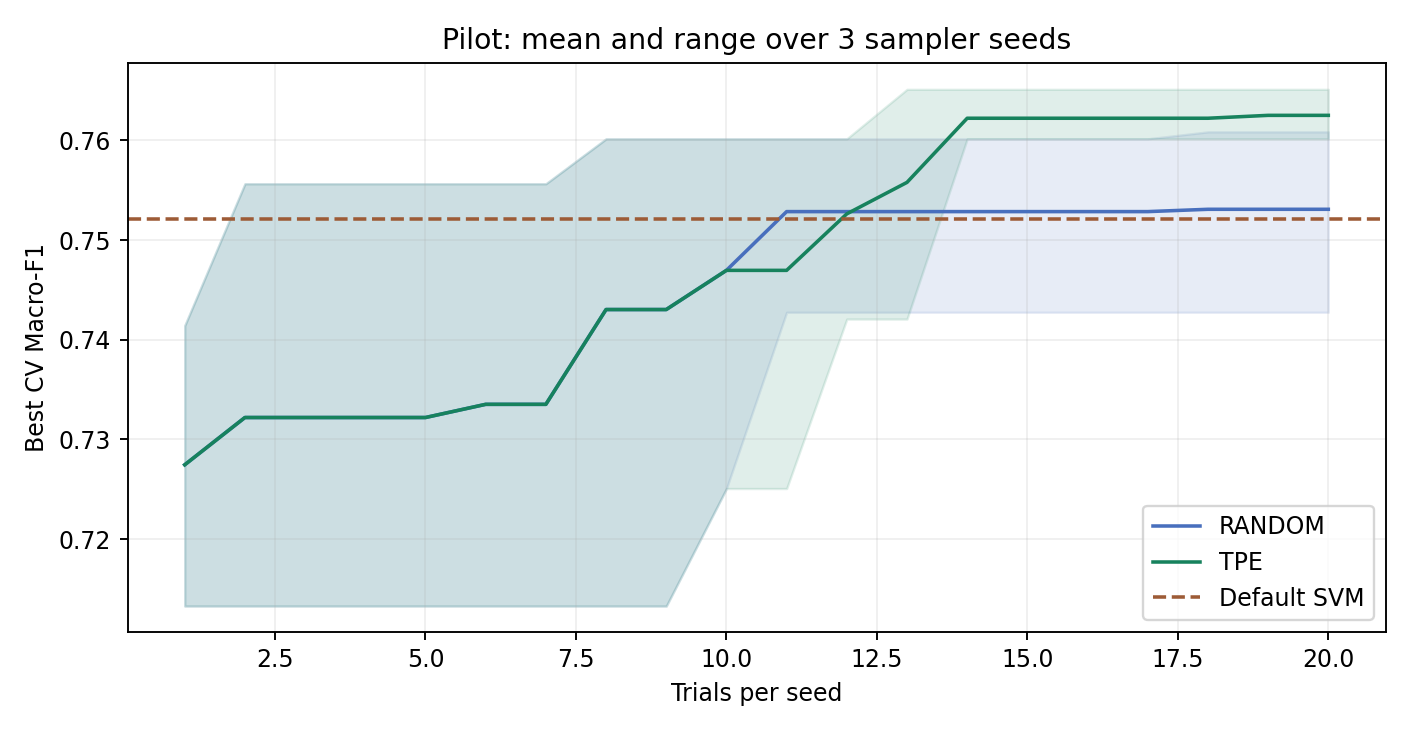

In [5]:
display(Image(filename=str(ROOT / 'results/figures/convergence.png'), width=850))

## 3. Cấu hình được chọn và giới hạn
Chọn bằng CV trên development. Cần chốt thiết kế rồi mới chấm 194 ảnh test. Không so trực tiếp với số liệu bài báo dùng khác loài, ảnh hoặc split. Mô hình chưa nhận biết loài lạ.

In [6]:
selection = json.loads((ROOT / 'results/pilot/selection.json').read_text())
print(json.dumps(selection['winner'], ensure_ascii=False, indent=2))
print((ROOT / 'results/verification.txt').read_text())

{
  "method": "tpe",
  "seed": 47,
  "best_cv_macro_f1": 0.7651317568039763,
  "fold_scores": [
    0.7621950093677747,
    0.759412099913892,
    0.773788161130262
  ],
  "params": {
    "kernel": "rbf",
    "C": 12.166217432892713,
    "gamma": 0.0005503827892904765
  },
  "best_trial": 13,
  "seconds": 7.238807485000052
}
test_cache_excludes_test_images (test_research.ResearchChecks.test_cache_excludes_test_images) ... ok
test_equal_budgets_and_summary_matches_logs (test_research.ResearchChecks.test_equal_budgets_and_summary_matches_logs) ... ok
test_image_to_saved_model_roundtrip (test_research.ResearchChecks.test_image_to_saved_model_roundtrip) ... ok
test_manifest_matches_model_and_protocol (test_research.ResearchChecks.test_manifest_matches_model_and_protocol) ... ok
test_no_image_or_group_leakage (test_research.ResearchChecks.test_no_image_or_group_leakage) ... ok
test_scaler_fits_only_training_rows_in_cv (test_research.ResearchChecks.test_scaler_fits_only_training_rows_in_cv) 

## 4. Tái lập bằng terminal
Chạy tại thư mục dự án (đọc README để tạo môi trường):

```bash
python -m pip install -r requirements.txt
python -m src.download
python -m src.audit --images data/raw --out data/audit_recheck
python -m src.experiment --trials 20 --out results/reproduction
python -m unittest discover -s tests -v
```

Giữ nguyên bản kê `data/audit/manifest.csv`. Lệnh thí nghiệm không chấm test. Notebook đã được chạy tuần tự bằng IPython trong cùng tiến trình; chưa kiểm tra giao diện Jupyter/VS Code.